# Huấn luyện và đánh giá — Tuần 6

So sánh Logistic Regression, Random Forest, LightGBM và mốc tham chiếu luôn dự đoán lớp đa số. Dùng cách chia đã lưu từ tuần 4 và đặc trưng tính từ chuỗi URL. Việc đọc và phân tích URL chạy tại chỗ.

**Chạy lại:** mở thư mục dự án trong VS Code, chọn kernel Python 3.12 với các thư viện trong README, rồi chọn **Run All**. Việc khớp TF-IDF, kiểm định chéo và huấn luyện lại có thể mất vài phút.

## 1. Nạp cách chia và kiểm tra nhóm

Nhãn gốc UCI là **0 = lừa đảo, 1 = hợp lệ**. Khi huấn luyện và tính chỉ số, biến `is_phishing` dùng **1 = lừa đảo** để Precision, Recall, F1 và điểm ROC-AUC luôn hướng về lớp cần phát hiện. Dữ liệu nguồn và tệp chia tập vẫn dùng quy ước gốc.

In [1]:
from itertools import combinations
from pathlib import Path
import io
import ipaddress
import string
from urllib.parse import urlsplit

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from lightgbm import LGBMClassifier
from scipy import sparse
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
import tldextract

data_dir = Path("data")
raw = pd.read_csv(data_dir / "PhiUSIIL_Phishing_URL_Dataset.csv", usecols=["URL", "label"],
                  dtype={"URL": "string"}, keep_default_na=False, na_values=[""])
manifest = pd.read_csv(data_dir / "splits.csv", index_col="source_row")
assert raw.shape == (235795, 2) and len(manifest) == 235370
assert manifest.index.is_unique and manifest.index.isin(raw.index).all()
assert set(manifest["split"]) == {"train", "validation", "test"}
data = raw.loc[manifest.index].join(manifest)
assert data["URL"].notna().all() and data["URL"].is_unique
assert set(data["label"]) == {0, 1}

def normalized_host(url):
    host = urlsplit(url).hostname.rstrip(".").lower()
    try:
        return str(ipaddress.ip_address(host))
    except ValueError:
        return host.encode("idna").decode("ascii")

hosts = data["URL"].map(normalized_host)
extract = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=True)
domains = {host: extract(host) for host in hosts.unique()}
group_by_host = {host: parts.top_domain_under_public_suffix or host for host, parts in domains.items()}
data["domain_group"] = hosts.map(group_by_host)
data["is_phishing"] = data["label"].eq(0).astype(int)
parts = {name: data.loc[data["split"].eq(name)] for name in ("train", "validation", "test")}
for a, b in combinations(parts.values(), 2):
    assert set(a["domain_group"]).isdisjoint(b["domain_group"])

display(data.groupby("split")["is_phishing"].agg(URL="size", phishing="sum"))

,URL,phishing
split,,
test,36229,15744
train,164785,70709
validation,34356,14067


## 2. Thuật toán và quy trình

| Mô hình | Lý do chọn và tham số chính |
|---|---|
| Mốc lớp đa số | Luôn dự đoán lớp phổ biến nhất ở phần huấn luyện. Đây là mốc F1 tham chiếu đã nêu ở tuần 4. |
| Logistic Regression | Mô hình tuyến tính tối thiểu hóa log-loss có phạt L2. Phù hợp với TF-IDF thưa. `C=1` điều khiển mức phạt. |
| Random Forest | Trung bình xác suất từ các cây huấn luyện trên mẫu bootstrap, dùng độ giảm Gini để tách. 48 cây, giới hạn độ sâu 18 và lá tối thiểu 4 mẫu để kiểm soát độ phức tạp và thời gian. |
| LightGBM | Tăng cường cây theo gradient của binary log-loss để học tương tác phi tuyến. 90 cây, tốc độ học 0,10, tối đa 31 lá và lấy 40% đặc trưng cho mỗi cây để giới hạn chi phí. |

Cấu hình và ngưỡng mặc định được cố định trước khi chạy. Mỗi lượt chia có một scaler và một TF-IDF riêng, chỉ khớp trên phần huấn luyện của lượt đó. Các mô hình dùng chung hai ma trận đã biến đổi trong cùng lượt để tránh lặp lại tiền xử lý. Công thức đặc trưng giữ như tuần 4.

[Tài liệu LightGBM](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html)

In [2]:
seed = 42
threads = 6
baseline = "Mốc lớp đa số"
models = {
    baseline: DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(C=1.0, solver="liblinear", max_iter=250, random_state=seed),
    "Random Forest": RandomForestClassifier(n_estimators=48, max_depth=18, min_samples_leaf=4,
                                             random_state=seed, n_jobs=threads),
    "LightGBM": LGBMClassifier(objective="binary", n_estimators=90, learning_rate=0.10,
                               num_leaves=31, colsample_bytree=0.40, max_bin=31,
                               random_state=seed, n_jobs=threads, verbosity=-1, force_col_wise=True),
}
keywords = ("login", "verify", "account", "secure", "update", "password")
punctuation = set(string.punctuation)
numeric_columns = ["url_length", "host_length", "digit_count", "punctuation_count",
                   "dot_count", "hyphen_count", "slash_count", "query_marker_count",
                   "subdomain_count", "is_ip", "keyword_count"]

def host_features(host):
    try:
        ipaddress.ip_address(host)
        return 0, 1
    except ValueError:
        subdomain = domains[host].subdomain
        return (len(subdomain.split(".")) if subdomain else 0), 0

host_metrics = {host: host_features(host) for host in domains}

def lexical_features(frame):
    rows = []
    for url, host in zip(frame["URL"], hosts.loc[frame.index], strict=True):
        subdomains, is_ip = host_metrics[host]
        lower_url = url.lower()
        rows.append((len(url), len(host), sum(ch.isdigit() for ch in url),
                     sum(ch in punctuation for ch in url), url.count("."), url.count("-"),
                     url.count("/"), url.count("?"), subdomains, is_ip,
                     sum(keyword in lower_url for keyword in keywords)))
    return pd.DataFrame(rows, index=frame.index, columns=numeric_columns, dtype=np.float32)

def combine(numeric, ngrams):
    return sparse.hstack([sparse.csr_matrix(numeric), ngrams], format="csr")

def fit_features(frame, lexical):
    scaler = StandardScaler()
    tfidf = TfidfVectorizer(analyzer="char", ngram_range=(3, 5), lowercase=False,
                           min_df=3, max_features=20_000, dtype=np.float32)
    matrix = combine(scaler.fit_transform(lexical), tfidf.fit_transform(frame["URL"]))
    assert int(scaler.n_samples_seen_) == len(frame)
    return matrix, scaler, tfidf

def transform_features(frame, lexical, scaler, tfidf):
    return combine(scaler.transform(lexical), tfidf.transform(frame["URL"]))

def evaluate(model, matrix, y):
    pred = model.predict(matrix)
    positive_column = np.flatnonzero(model.classes_ == 1).item()
    prob = model.predict_proba(matrix)[:, positive_column]
    return {
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, prob),
    }, pred, prob

## 3. Kiểm định chéo trên train

`StratifiedGroupKFold` chia **3 lượt** theo tên miền, cố gắng cân bằng nhãn giữa các lượt. Mỗi lượt kiểm tra rằng hai phần không trùng nhóm và đều có hai lớp. Bảng tổng hợp dùng trung bình và độ lệch chuẩn mẫu giữa ba lượt.

In [3]:
train = parts["train"]
train_lexical = lexical_features(train)
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed)
cv_rows = []
fold_rows = []
for fold, (fit_idx, check_idx) in enumerate(
        cv.split(train, train["is_phishing"], groups=train["domain_group"]), start=1):
    fit, check = train.iloc[fit_idx], train.iloc[check_idx]
    assert set(fit["domain_group"]).isdisjoint(check["domain_group"])
    assert fit["is_phishing"].nunique() == check["is_phishing"].nunique() == 2
    fold_rows.append({"Lượt": fold, "URL học": len(fit), "URL kiểm định": len(check),
                      "Tỷ lệ phishing kiểm định (%)": 100 * check["is_phishing"].mean()})
    X_fit, scaler, tfidf = fit_features(fit, train_lexical.loc[fit.index])
    X_check = transform_features(check, train_lexical.loc[check.index], scaler, tfidf)
    for name, spec in models.items():
        model = clone(spec).fit(X_fit, fit["is_phishing"])
        metrics, _, _ = evaluate(model, X_check, check["is_phishing"])
        cv_rows.append({"Mô hình": name, "Lượt": fold, **metrics})
        print(f"Lượt {fold} · {name} · F1 = {metrics['F1']:.4f}", flush=True)

metric_columns = ["Precision", "Recall", "F1", "ROC-AUC"]
cv_scores = pd.DataFrame(cv_rows)
cv_summary = cv_scores.groupby("Mô hình", sort=False)[metric_columns].agg(["mean", "std"])
display(pd.DataFrame(fold_rows).round(2))
display(cv_summary.round(4))

Lượt 1 · Mốc lớp đa số · F1 = 0.0000
Lượt 1 · Logistic Regression · F1 = 0.9958
Lượt 1 · Random Forest · F1 = 0.9931
Lượt 1 · LightGBM · F1 = 0.9975
Lượt 2 · Mốc lớp đa số · F1 = 0.0000
Lượt 2 · Logistic Regression · F1 = 0.9951
Lượt 2 · Random Forest · F1 = 0.9934
Lượt 2 · LightGBM · F1 = 0.9976
Lượt 3 · Mốc lớp đa số · F1 = 0.0000
Lượt 3 · Logistic Regression · F1 = 0.9962
Lượt 3 · Random Forest · F1 = 0.9934
Lượt 3 · LightGBM · F1 = 0.9983


,Lượt,URL học,URL kiểm định,Tỷ lệ phishing kiểm định (%)
0,1,111387,53398,41.17
1,2,110960,53825,41.78
2,3,107223,57562,45.59


Precision          Recall  ...         ROC-AUC        
                         mean     std    mean  ...     std    mean     std
Mô hình                                        ...                        
Mốc lớp đa số          0.0000  0.0000  0.0000  ...  0.0000  0.5000  0.0000
Logistic Regression    1.0000  0.0000  0.9915  ...  0.0006  0.9989  0.0003
Random Forest          0.9988  0.0006  0.9880  ...  0.0002  0.9987  0.0002
LightGBM               1.0000  0.0001  0.9957  ...  0.0004  0.9989  0.0002

[4 rows x 8 columns]

## 4. So sánh trên validation và chọn mô hình

Khớp lại tiền xử lý trên toàn bộ train rồi đánh giá ba mô hình và mốc cơ sở trên validation. Chọn mô hình có F1 phishing cao nhất trên validation. Nếu bằng F1, ưu tiên ROC-AUC rồi tên mô hình để kết quả có thể tái lập. Chênh lệch F1 giữa train và validation là dấu hiệu cần xem cùng với thay đổi tên miền giữa hai tập.

In [4]:
validation = parts["validation"]
X_train, final_scaler, final_tfidf = fit_features(train, train_lexical)
X_val = transform_features(validation, lexical_features(validation), final_scaler, final_tfidf)
validation_rows = []
fitted_models = {}
for name, spec in models.items():
    model = clone(spec).fit(X_train, train["is_phishing"])
    fitted_models[name] = model
    train_f1 = f1_score(train["is_phishing"], model.predict(X_train), zero_division=0)
    metrics, _, _ = evaluate(model, X_val, validation["is_phishing"])
    validation_rows.append({"Mô hình": name, **metrics, "F1 train": train_f1,
                            "Chênh lệch F1": train_f1 - metrics["F1"]})
    print(f"Validation · {name} · F1 = {metrics['F1']:.4f}", flush=True)

val_scores = pd.DataFrame(validation_rows).set_index("Mô hình")
ranked = val_scores.drop(index=baseline).reset_index().sort_values(
    ["F1", "ROC-AUC", "Mô hình"], ascending=[False, False, True])
chosen = ranked.iloc[0]["Mô hình"]
runner_up = ranked.iloc[1]["Mô hình"]
winner = fitted_models[chosen]
display(val_scores.round(4))
display(Markdown(
    f"**Chọn {chosen}.** F1 validation là {val_scores.loc[chosen, 'F1']:.4f}, "
    f"so với {val_scores.loc[runner_up, 'F1']:.4f} của {runner_up}. "
    f"F1 train là {val_scores.loc[chosen, 'F1 train']:.4f}; "
    f"chênh lệch train–validation là {val_scores.loc[chosen, 'Chênh lệch F1']:+.4f}."
))

Validation · Mốc lớp đa số · F1 = 0.0000
Validation · Logistic Regression · F1 = 0.9956
Validation · Random Forest · F1 = 0.9928
Validation · LightGBM · F1 = 0.9976


,Precision,Recall,F1,ROC-AUC,F1 train,Chênh lệch F1
Mô hình,,,,,,
Mốc lớp đa số,0.0000,0.0000,0.0000,0.5000,0.0000,0.0000
Logistic Regression,1.0000,0.9912,0.9956,0.9984,0.9968,0.0012
Random Forest,0.9994,0.9864,0.9928,0.9982,0.9942,0.0014
LightGBM,1.0000,0.9952,0.9976,0.9987,0.9984,0.0008


**Chọn LightGBM.** F1 validation là 0.9976, so với 0.9956 của Logistic Regression. F1 train là 0.9984; chênh lệch train–validation là +0.0008.

## 5. Đánh giá cuối trên test

Tập test chỉ được dùng ở đây sau khi chốt mô hình. Mốc đa số được đo trên cùng tập để đối chiếu. Ma trận nhầm lẫn đặt nhãn **hợp lệ** trước, **lừa đảo** sau.

C:\Users\TTTT\AppData\Local\Temp\phishing-eda-aef5794acdb94110836a4278dcdba049\Lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


,Precision,Recall,F1,ROC-AUC
Mốc lớp đa số,0.0,0.0000,0.000,0.5000
LightGBM,1.0,0.9959,0.998,0.9989


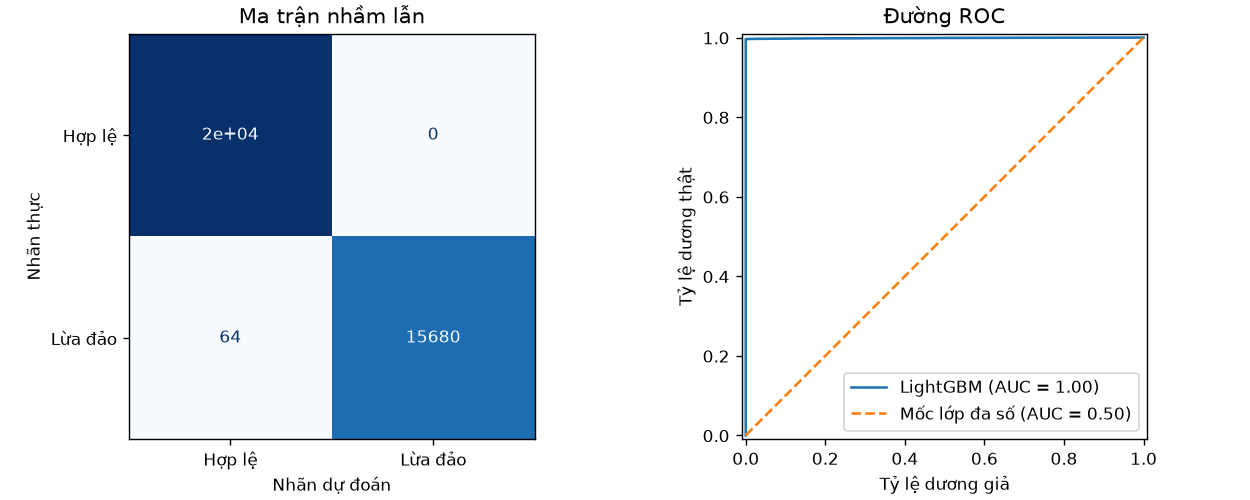

In [5]:
test = parts["test"]
X_test = transform_features(test, lexical_features(test), final_scaler, final_tfidf)
y_test = test["is_phishing"]
test_metrics, test_pred, test_prob = evaluate(winner, X_test, y_test)
base_metrics, _, base_prob = evaluate(fitted_models[baseline], X_test, y_test)
display(pd.DataFrame({baseline: base_metrics, chosen: test_metrics}).T.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred, labels=[0, 1]),
                       display_labels=["Hợp lệ", "Lừa đảo"]).plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set(title="Ma trận nhầm lẫn", xlabel="Nhãn dự đoán", ylabel="Nhãn thực")
RocCurveDisplay.from_predictions(y_test, test_prob, ax=axes[1], name=chosen)
RocCurveDisplay.from_predictions(y_test, base_prob, ax=axes[1], name=baseline, linestyle="--")
axes[1].set(title="Đường ROC", xlabel="Tỷ lệ dương giả", ylabel="Tỷ lệ dương thật")
buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=125)
plt.close(fig)
display(Image(data=buffer.getvalue()))

## 6. Phân tích lỗi và đặc trưng

So sánh lỗi theo độ dài URL và số tên miền con. FNR là tỷ lệ URL lừa đảo bị bỏ sót trong nhóm. FPR là tỷ lệ URL hợp lệ bị cảnh báo nhầm. Chỉ so sánh các tỷ lệ có ít nhất 100 mẫu thuộc lớp tương ứng để giảm ảnh hưởng của nhóm rất nhỏ.

In [6]:
test_lexical = lexical_features(test)
errors = pd.DataFrame({"actual": y_test.to_numpy(), "pred": test_pred}, index=test.index)
errors["FN"] = errors["actual"].eq(1) & errors["pred"].eq(0)
errors["FP"] = errors["actual"].eq(0) & errors["pred"].eq(1)
errors["legit"] = errors["actual"].eq(0)

buckets = {
    "Độ dài": pd.cut(test_lexical["url_length"], [0, 25, 40, 80, np.inf],
                     labels=["≤25", "26–40", "41–80", ">80"]),
    "Tên miền con": test_lexical["subdomain_count"].clip(upper=2).astype(int).map(
        {0: "0", 1: "1", 2: "2+"}),
}
tables = []
for key, groups in buckets.items():
    table = errors.groupby(groups, observed=True).agg(
        N=("actual", "size"), phishing=("actual", "sum"), legit=("legit", "sum"),
        FN=("FN", "sum"), FP=("FP", "sum"))
    table["FNR (%)"] = 100 * table["FN"] / table["phishing"].replace(0, np.nan)
    table["FPR (%)"] = 100 * table["FP"] / table["legit"].replace(0, np.nan)
    table.index = table.index.rename("Khoảng")
    tables.append(table.assign(Đặc_trưng=key).set_index("Đặc_trưng", append=True).swaplevel())
error_summary = pd.concat(tables)
display(error_summary.round(2))
fn_group = error_summary.loc[error_summary["phishing"].ge(100), "FNR (%)"].idxmax()
fp_group = error_summary.loc[error_summary["legit"].ge(100), "FPR (%)"].idxmax()
fp_note = ("Mọi nhóm đủ mẫu đều có FPR bằng 0%." if not errors["FP"].any() else
           f"FPR cao nhất trong các nhóm đủ mẫu: **{fp_group[0]} {fp_group[1]}** "
           f"({error_summary.loc[fp_group, 'FPR (%)']:.2f}%).")
display(Markdown(
    f"- Bỏ sót **{int(errors['FN'].sum()):,}** URL phishing và cảnh báo nhầm "
    f"**{int(errors['FP'].sum()):,}** URL hợp lệ.\n"
    f"- FNR cao nhất trong các nhóm đủ mẫu: **{fn_group[0]} {fn_group[1]}** "
    f"({error_summary.loc[fn_group, 'FNR (%)']:.2f}%).\n"
    f"- {fp_note}"
))

feature_names = [*numeric_columns, *final_tfidf.get_feature_names_out()]
for name, model in fitted_models.items():
    if name == baseline:
        continue
    if name == "Logistic Regression":
        weights = model.coef_[0]
        order = np.argsort(np.abs(weights))[-8:][::-1]
        measure = "Hệ số (dương hướng phishing)"
    elif name == "LightGBM":
        weights = model.booster_.feature_importance(importance_type="gain")
        order = np.argsort(weights)[-8:][::-1]
        measure = "Gain"
    else:
        weights = model.feature_importances_
        order = np.argsort(weights)[-8:][::-1]
        measure = "Độ giảm impurity"
    print(name)
    display(pd.DataFrame({"Đặc trưng": [feature_names[i] for i in order],
                          measure: weights[order]}).round(4))

Logistic Regression
Random Forest
LightGBM


N  phishing  legit  FN  FP  FNR (%)  FPR (%)
Đặc_trưng    Khoảng                                                  
Độ dài       ≤25     11326      3454   7872  23   0     0.67      0.0
             26–40   18512      6080  12432  40   0     0.66      0.0
             41–80    4533      4352    181   1   0     0.02      0.0
             >80      1858      1858      0   0   0     0.00      NaN
Tên miền con 0        5396      5392      4   0   0     0.00      0.0
             1       28189      8464  19725  63   0     0.74      0.0
             2+       2644      1888    756   1   0     0.05      0.0

- Bỏ sót **64** URL phishing và cảnh báo nhầm **0** URL hợp lệ.
- FNR cao nhất trong các nhóm đủ mẫu: **Tên miền con 1** (0.74%).
- Mọi nhóm đủ mẫu đều có FPR bằng 0%.

,Đặc trưng,Hệ số (dương hướng phishing)
0,s://w,-12.9310
1,p://w,12.5151
2,p://,11.4574
3,tp://,11.4574
4,ttp:/,11.4573
5,ttp:,11.4573
6,p:/,11.4573
7,tp:/,11.4573


,Đặc trưng,Độ giảm impurity
0,http:,0.0622
1,ttp:/,0.0468
2,//ww,0.0435
3,/ww,0.0392
4,s://,0.0382
5,https,0.0370
6,//www,0.0312
7,p:/,0.0307


,Đặc trưng,Gain
0,s://w,674431.6797
1,ps://,119698.0961
2,tps:/,71237.5947
3,/www.,62082.6774
4,//www,49333.0698
5,slash_count,43788.1883
6,ps:/,36393.4395
7,www.,28881.8395


Hệ số Logistic Regression cho biết hướng tác động trong mô hình sau biến đổi. Gain và độ giảm impurity cho biết cây dựa vào đặc trưng nào để tách, với đơn vị khác nhau theo mô hình. Một n-gram có thể đại diện một phần của cấu trúc URL. Các đặc trưng thường đi cùng nhau có thể chia sẻ mức ảnh hưởng.

**Vấn đáp cá nhân:** giải thích vì sao giữ các tên miền tách biệt, vì sao cần khớp lại TF-IDF trong từng lượt và cách đọc Precision/Recall của lớp phishing. Để thực hành, thay `max_depth` của Random Forest hoặc thêm một chỉ số vào hàm `evaluate`, rồi đối chiếu trên validation.

### Giới hạn của kết quả trên PhiUSIIL

Kiểm tra thêm cấu trúc URL trong train để xem liệu sự khác biệt trong cách thu thập hai lớp có thể ảnh hưởng đến kết quả.

In [7]:
def url_structure(url):
    parts = urlsplit(url)
    return parts.path not in ("", "/"), bool(parts.query)

structure = pd.DataFrame(train["URL"].map(url_structure).tolist(), index=train.index,
                         columns=["Đường dẫn khác gốc", "Có query"])
rates = structure.groupby(train["label"]).mean().mul(100)
display(rates.rename(index={0: "Lừa đảo", 1: "Hợp lệ"}).round(2))

,Đường dẫn khác gốc,Có query
label,,
Lừa đảo,26.87,5.49
Hợp lệ,0.00,0.00


Trong train, 26,87% URL phishing có đường dẫn khác gốc và 5,49% có query. Cả hai tỷ lệ đều bằng 0 ở URL hợp lệ. Mô hình có thể học một phần sự khác biệt trong cách lấy mẫu của bộ dữ liệu. Kết quả test theo tên miền đo khả năng tổng quát trong PhiUSIIL. Để ước lượng hiệu quả trên dữ liệu thực tế, cần kiểm tra thêm trên nguồn độc lập có URL hợp lệ chứa đường dẫn và query.

Trên validation, LightGBM tăng Recall lên 0,9952 so với 0,9912 của Logistic Regression, với Precision của cả hai đều đạt 1,0000. Các đặc trưng có ảnh hưởng lớn ở cả ba mô hình gồm mảnh chuỗi thuộc giao thức và tiền tố tên máy chủ. LightGBM còn xếp số dấu gạch chéo trong nhóm có gain cao. Các bảng này cho thấy mô hình sử dụng tín hiệu nào, còn mức tăng Recall cần được kiểm chứng riêng nếu muốn quy cho một đặc trưng cụ thể.